# 1D estacionario en diferencias finitas

Mismo modelo de Kozono & Koyaguchi (2009) que `RIconduitex5_5_f` / `RIconduitef5_5_f`, marchado en $z$ con RK4. **No usa `scikits.odes` / IDA.**

- **Pre-fragmentación:** HEM + ecuación de estado ($u_m = u_g$).
- **Post-fragmentación:** las mismas ecuaciones bifásicas de Kozono que usa IDA (`n_eq = 4`): $\varphi$ es independiente, $u_g$ se separa de $u_m$.
- **Rama explosiva:** tiro sobre $v_\mathrm{inicial}$ (boca sónica o $P \approx P_\mathrm{atm}$ con fragmentación).
- **Rama efusiva:** el mismo conducto, pero el tiro pide $P \approx P_\mathrm{atm}$ en $z \approx 0$ **sin** cruzar $\varphi_\mathrm{crit}$.

Parámetros: Calbuco 2015 (`calbuco2015d.py`). Ejecutar todas las celdas.

Para la actividad de curso (tres volcanes, solo se editan datos): `actividad_conducto1D.ipynb`.


In [1]:
%matplotlib inline
import os
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, os.getcwd())

from calbuco2015d import (
    H, Patm, T1, geometry, h2o1, overP1, phicrit, radius1, xi1,
)
from RIconduit1D_FD import RIconduit1D_FD_f
from RIconduitef5_5 import RIconduitef5_5_f

print("Parámetros Calbuco 2015")
print(f"  radio        = {radius1} m")
print(f"  sobrepresión = {overP1/1e6:.1f} MPa")
print(f"  H2O          = {h2o1} wt%")
print(f"  T            = {T1-273.15:.0f} °C")
print(f"  xi           = {xi1}")
print(f"  H            = {H/1e3:.1f} km")
print(f"  φ_crit input = {phicrit}")
print(f"  geometría    = {geometry}")

Parámetros Calbuco 2015
  radio        = 16 m
  sobrepresión = 5.0 MPa
  H2O          = 4 wt%
  T            = 970 °C
  xi           = 0.25
  H            = -7.0 km
  φ_crit input = 0.8
  geometría    = cylinder


## Rama explosiva: tiro + marcha en $z$

`RIconduit1D_FD_f` (o `RIconduitex5_5_f`) busca $v_\mathrm{inicial}$ para boca sónica. El default ya es diferencias finitas.

In [2]:
(
    zsol, sol, count, vinicial, rho_m, rbub, visc,
    rho_ti, fragcrit, phicrit_run, limphi1, limphi2, co, xi, xfinal, cg,
) = RIconduit1D_FD_f(radius1, overP1, h2o1, T1, xi1)


Count = 1 
Initial velocity = 10.0 

Velocidad de salida: 34.815573657970496 
Presión de salida: 11518168.458929587 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.6993798032874333
vmax: 50.0 
vmin: 10.0

Count = 2 
Initial velocity = 30.0 



Velocidad de salida: 798.7482204044185 
Presión de salida: 1560500.3518691459 
Profundidad de salida: -1161.1729692482409 
Contenido de burbujas de salida: 0.8936115392985848
vmax: 30.0 
vmin: 10.0

Count = 3 
Initial velocity = 20.0 

Velocidad de salida: 773.9132259420218 
Presión de salida: 1068319.5471745313 
Profundidad de salida: -182.21121352484874 
Contenido de burbujas de salida: 0.9201287377371656
vmax: 20.0 
vmin: 10.0

Count = 4 
Initial velocity = 15.0 



Velocidad de salida: 69.88976816989208 
Presión de salida: 8317037.358609634 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.7796791393791292
vmax: 20.0 
vmin: 15.0

Count = 5 
Initial velocity = 17.5 

Velocidad de salida: 105.1425471920512 
Presión de salida: 6376727.322402874 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.8283934553795778
vmax: 20.0 
vmin: 17.5

Count = 6 
Initial velocity = 18.75 



Velocidad de salida: 825.5282879140603 
Presión de salida: 940901.1853020284 
Profundidad de salida: -26.509888572804584 
Contenido de burbujas de salida: 0.9246549491133862
vmax: 18.75 
vmin: 17.5

Count = 7 
Initial velocity = 18.125 

Velocidad de salida: 126.65604110147105 
Presión de salida: 5474738.897380529 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.8501572747383228
vmax: 18.75 
vmin: 18.125

Count = 8 
Initial velocity = 18.4375 



Velocidad de salida: 161.83025204690387 
Presión de salida: 4377142.12559927 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.873891469938598
vmax: 18.75 
vmin: 18.4375

Count = 9 
Initial velocity = 18.59375 

Velocidad de salida: 777.739882910277 
Presión de salida: 987901.8913975093 
Profundidad de salida: -6.4018957576761295 
Contenido de burbujas de salida: 0.9245568399729849
vmax: 18.59375 
vmin: 18.4375

Count = 10 
Initial velocity = 18.515625 



Velocidad de salida: 213.214158232092 
Presión de salida: 3374244.138377849 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.8918678980957011
vmax: 18.59375 
vmin: 18.515625

Count = 11 
Initial velocity = 18.5546875 

Velocidad de salida: 822.3386450925524 
Presión de salida: 934478.1044372276 
Profundidad de salida: -1.35081975651633 
Contenido de burbujas de salida: 0.9252237542643629
vmax: 18.5546875 
vmin: 18.515625

Count = 12 
Initial velocity = 18.53515625 



Velocidad de salida: 289.57729882848366 
Presión de salida: 2525499.1456233943 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.9048015121477895
vmax: 18.5546875 
vmin: 18.53515625

Count = 13 
Initial velocity = 18.544921875 

Velocidad de salida: 776.1474997665464 
Presión de salida: 987223.8642683753 
Profundidad de salida: -0.08570486031430846 
Contenido de burbujas de salida: 0.9246905008310202
>>> Solucion de tiro convergida.


In [3]:
P, phi, Nd, x_cr, um, ug = (sol[:, i] for i in range(6))
z_km = zsol / 1e3

if geometry == "dyke":
    from calbuco2015d import dl
    Q = vinicial * radius1 * dl
else:
    Q = vinicial * np.pi * radius1 ** 2

frag = np.where(phi >= phicrit_run)[0]
z_frag = zsol[frag[0]] if frag.size else np.nan

print("Resumen")
print(f"  tiros          = {count}")
print(f"  vinicial       = {vinicial:.4f} m/s")
print(f"  Q              = {Q*rho_ti:.3g} kg/s")
print(f"  z_boca         = {zsol[-1]:.2f} m")
print(f"  P_boca         = {P[-1]/1e5:.3f} bar   (P_atm = {Patm/1e5:.3f} bar)")
print(f"  φ_boca         = {phi[-1]:.4f}")
print(f"  um, ug boca    = {um[-1]:.2f}, {ug[-1]:.2f} m/s")
print(f"  φ_crit (Ca)    = {phicrit_run:.3f}")
print(f"  lim φ perm.    = [{limphi1:.3f}, {limphi2:.3f}]")
if frag.size:
    print(f"  fragmentación  = {z_frag/1e3:.2f} km  ({frag.size} nodos)")
else:
    print("  fragmentación  = no alcanzada")

Resumen
  tiros          = 13
  vinicial       = 18.5449 m/s
  Q              = 3.67e+07 kg/s
  z_boca         = -0.09 m
  P_boca         = 9.872 bar   (P_atm = 1.013 bar)
  φ_boca         = 0.9247
  um, ug boca    = 239.59, 776.15 m/s
  φ_crit (Ca)    = 0.580
  lim φ perm.    = [0.347, 0.357]
  fragmentación  = -1.30 km  (666 nodos)


## Perfiles a lo largo del conducto

Misma disposición de seis paneles que `mainconduit5_5.ipynb`.

<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_22399/2172570608.py:32: SyntaxWarning: invalid escape sequence '\m'
  f"1D FD — Calbuco    $v_\mathrm{{in}}$ = {vinicial:.2f} m/s",


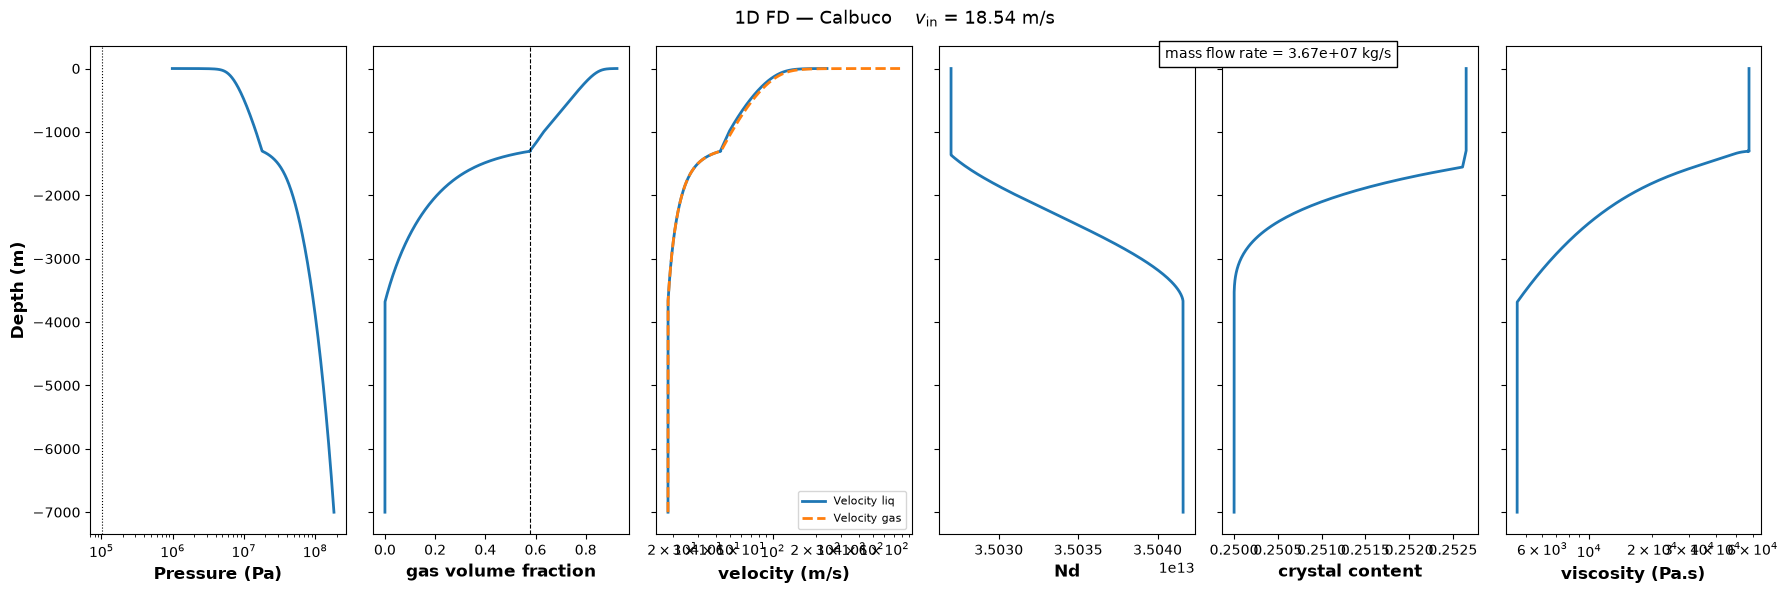

In [4]:
fig, axs = plt.subplots(1, 6, figsize=(18, 6), sharey=True)

axs[0].semilogx(P, zsol, linewidth=2)
axs[0].axvline(Patm, color="k", ls=":", lw=0.8)
axs[0].set_xlabel("Pressure (Pa)", fontweight="bold", fontsize=12)
axs[0].set_ylabel("Depth (m)", fontweight="bold", fontsize=12)

axs[1].plot(phi, zsol, linewidth=2)
axs[1].axvline(phicrit_run, color="k", ls="--", lw=0.8)
axs[1].set_xlabel("gas volume fraction", fontweight="bold", fontsize=12)

axs[2].semilogx(um, zsol, label="Velocity liq", linewidth=2)
axs[2].semilogx(ug, zsol, "--", label="Velocity gas", linewidth=2)
axs[2].set_xlabel("velocity (m/s)", fontweight="bold", fontsize=12)
axs[2].legend(fontsize=8)

axs[3].plot(Nd, zsol, linewidth=2)
axs[3].set_xlabel("Nd", fontweight="bold", fontsize=12)

axs[4].plot(x_cr, zsol, linewidth=2)
axs[4].set_xlabel("crystal content", fontweight="bold", fontsize=12)

axs[5].semilogx(visc, zsol, linewidth=2)
axs[5].set_xlabel("viscosity (Pa.s)", fontweight="bold", fontsize=12)

fig.text(
    0.65, 0.90,
    f"mass flow rate = {Q * rho_ti:.3g} kg/s",
    bbox=dict(facecolor="white", edgecolor="black"),
)
fig.suptitle(
    f"1D FD — Calbuco    $v_\mathrm{{in}}$ = {vinicial:.2f} m/s",
    fontsize=13,
)
fig.tight_layout()
plt.show()

Presión, $\varphi$ y velocidades con profundidad en km. Después de fragmentar se grafican las $u_m,u_g$ del ODE ($f_g$ con cristales). El split grande aparece cerca de la boca; en el resto de la columna $u_g/u_m\approx 1.05$.

<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_22399/2597129338.py:27: SyntaxWarning: invalid escape sequence '\m'
  fig.suptitle(f"1D estacionario FD — Calbuco   $v_\mathrm{{in}} = {vinicial:.2f}$ m/s")


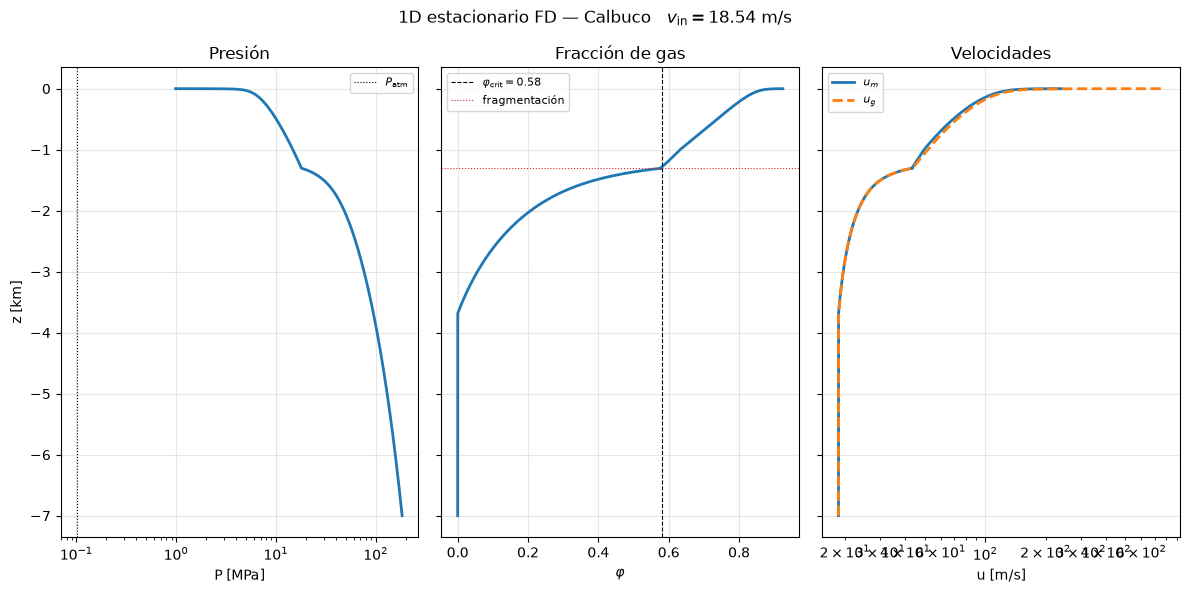

Figura: RIconduit1D_FD_calbuco.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharey=True)

axes[0].semilogx(P / 1e6, z_km, linewidth=2)
axes[0].axvline(Patm / 1e6, color="k", ls=":", lw=0.8, label=r"$P_\mathrm{atm}$")
axes[0].set_xlabel("P [MPa]")
axes[0].set_ylabel("z [km]")
axes[0].set_title("Presión")
axes[0].legend(fontsize=8)

axes[1].plot(phi, z_km, linewidth=2)
axes[1].axvline(phicrit_run, color="k", ls="--", lw=0.8, label=fr"$\varphi_\mathrm{{crit}} = {phicrit_run:.2f}$")
if frag.size:
    axes[1].axhline(z_frag / 1e3, color="C3", ls=":", lw=0.8, label="fragmentación")
axes[1].set_xlabel(r"$\varphi$")
axes[1].set_title("Fracción de gas")
axes[1].legend(fontsize=8)

axes[2].semilogx(um, z_km, linewidth=2, label=r"$u_m$")
axes[2].semilogx(ug, z_km, "--", linewidth=2, label=r"$u_g$")
axes[2].set_xlabel("u [m/s]")
axes[2].set_title("Velocidades")
axes[2].legend(fontsize=8)

for ax in axes:
    ax.grid(True, alpha=0.3)

fig.suptitle(f"1D estacionario FD — Calbuco   $v_\mathrm{{in}} = {vinicial:.2f}$ m/s")
fig.tight_layout()
plt.savefig("RIconduit1D_FD_calbuco.png", dpi=140, bbox_inches="tight")
plt.show()
print("Figura: RIconduit1D_FD_calbuco.png")

## Rama efusiva

Misma física y misma marcha FD, otro criterio de tiro (`RIconduitef5_5_f` / `rama='efusiva'`):

- $P_\mathrm{boca} \approx P_\mathrm{atm}$
- $z_\mathrm{boca} \approx 0$
- $\varphi_\mathrm{boca} \le \varphi_\mathrm{crit}$ (no fragmenta)

Con Calbuco 2015 (4 wt% H₂O, $R=16$ m) **no hay solución efusiva**: al borde de fragmentar la boca sigue a decenas de MPa. Se corre igual y se grafica el último tiro.

In [6]:
(
    zsol_ef, sol_ef, count_ef, vef, rho_m_ef, rbub_ef, visc_ef,
    rho_ti_ef, fragcrit_ef, phicrit_ef, limphi1_ef, limphi2_ef, co_ef, xi_ef, xfinal_ef, cg_ef,
) = RIconduitef5_5_f(radius1, overP1, h2o1, T1, xi1)


Count = 1 
Initial velocity = 0.1 

Velocidad de salida: 0.172479630264501 
Presión de salida: 27414918.410215795 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.4285419794240825
vmax: 5.0 
vmin: 0.1

Count = 2 
Initial velocity = 2.5500000000000003 

Velocidad de salida: 5.876205532226818 
Presión de salida: 19762855.782558523 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5176146373055173
vmax: 5.0 
vmin: 2.5500000000000003

Count = 3 
Initial velocity = 3.7750000000000004 



Velocidad de salida: 9.262238512618316 
Presión de salida: 17762428.448599923 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5633938946013337
vmax: 3.7750000000000004 
vmin: 2.5500000000000003

Count = 4 
Initial velocity = 3.1625000000000005 



Velocidad de salida: 7.415754780219085 
Presión de salida: 18683035.87722656 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5500000746019559
vmax: 3.1625000000000005 
vmin: 2.5500000000000003

Count = 5 
Initial velocity = 2.85625 

Velocidad de salida: 6.491686930294069 
Presión de salida: 19202745.593741808 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5462834070149942
vmax: 3.1625000000000005 
vmin: 2.85625

Count = 6 
Initial velocity = 3.0093750000000004 



Velocidad de salida: 7.01598404428216 
Presión de salida: 18932726.78510386 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5431272960800382
vmax: 3.1625000000000005 
vmin: 3.0093750000000004

Count = 7 
Initial velocity = 3.0859375000000004 



Velocidad de salida: 7.256733892559573 
Presión de salida: 18810126.28475037 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5433310037813873
vmax: 3.1625000000000005 
vmin: 3.0859375000000004

Count = 8 
Initial velocity = 3.1242187500000007 

Velocidad de salida: 7.105665735587964 
Presión de salida: 18746048.748234425 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5644223076780372
vmax: 3.1242187500000007 
vmin: 3.0859375000000004

Count = 9 
Initial velocity = 3.1050781250000004 



Velocidad de salida: 7.1109748555973304 
Presión de salida: 18770012.56345068 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5595577798014449
vmax: 3.1050781250000004 
vmin: 3.0859375000000004

Count = 10 
Initial velocity = 3.0955078125 



Velocidad de salida: 7.2293370165428765 
Presión de salida: 18793004.871748094 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5477710486465591
vmax: 3.1050781250000004 
vmin: 3.0955078125

Count = 11 
Initial velocity = 3.1002929687500003 

Velocidad de salida: 7.080797869692384 
Presión de salida: 18783537.653263446 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5605172026168467
vmax: 3.1002929687500003 
vmin: 3.0955078125

Count = 12 
Initial velocity = 3.097900390625 



Velocidad de salida: 7.285930104782298 
Presión de salida: 18789147.470462635 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5440907637600321
vmax: 3.1002929687500003 
vmin: 3.097900390625

Count = 13 
Initial velocity = 3.0990966796875004 



Velocidad de salida: 7.2441672819838745 
Presión de salida: 18786699.757494148 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.547537472881015
vmax: 3.1002929687500003 
vmin: 3.0990966796875004

Count = 14 
Initial velocity = 3.0996948242187505 

Velocidad de salida: 7.063185999452145 
Presión de salida: 18784342.019615076 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.561773191659298
vmax: 3.0996948242187505 
vmin: 3.0990966796875004

Count = 15 
Initial velocity = 3.0993957519531254 



Velocidad de salida: 7.1849807611072 
Presión de salida: 18785634.64461475 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5521444765867374
vmax: 3.0993957519531254 
vmin: 3.0990966796875004

Count = 16 
Initial velocity = 3.0992462158203127 



Velocidad de salida: 7.215252367825996 
Presión de salida: 18786215.88738926 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5497778547976759
vmax: 3.0992462158203127 
vmin: 3.0990966796875004

Count = 17 
Initial velocity = 3.0991714477539065 

Velocidad de salida: 7.229574638804937 
Presión de salida: 18786477.088144727 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.5486648935983138
vmax: 3.0992462158203127 
vmin: 3.0991714477539065
Intervalo de bisección agotado.
No hay solución efusiva: no se alcanza P_atm sin fragmentar. Ultima z=0.0 m, P=1.879e+07 Pa, phi=0.5487, ug=7.230 m/s.


In [7]:
P_ef, phi_ef, Nd_ef, x_cr_ef, um_ef, ug_ef = (sol_ef[:, i] for i in range(6))
z_km_ef = zsol_ef / 1e3

if geometry == "dyke":
    from calbuco2015d import dl
    Q_ef = vef * radius1 * dl
else:
    Q_ef = vef * np.pi * radius1 ** 2

solef = (
    count_ef < 49
    and abs(sol_ef[-1, 0] - Patm) < 0.05e5
    and zsol_ef[-1] > -2.0
    and sol_ef[-1, 1] <= phicrit_ef
)

print("Resumen efusiva")
print(f"  solución        = {'sí' if solef else 'no (no alcanza P_atm sin fragmentar)'}")
print(f"  tiros           = {count_ef}")
print(f"  vinicial        = {vef:.4f} m/s")
print(f"  Q               = {Q_ef * rho_ti_ef:.3e} kg/s")
print(f"  z_boca          = {zsol_ef[-1]:.2f} m")
print(f"  P_boca          = {sol_ef[-1, 0]/1e5:.3f} bar   (P_atm = {Patm/1e5:.3f} bar)")
print(f"  φ_boca          = {sol_ef[-1, 1]:.4f}   (φ_crit = {phicrit_ef:.3f})")
print(f"  um, ug boca     = {um_ef[-1]:.2f}, {ug_ef[-1]:.2f} m/s")

Resumen efusiva
  solución        = no (no alcanza P_atm sin fragmentar)
  tiros           = 17
  vinicial        = 3.0992 m/s
  Q               = 6.140e+06 kg/s
  z_boca          = 0.00 m
  P_boca          = 187.865 bar   (P_atm = 1.013 bar)
  φ_boca          = 0.5487   (φ_crit = 0.549)
  um, ug boca     = 6.75, 7.23 m/s


Perfiles efusivos (seis paneles, mismo estilo que la explosiva / `mainconduit5_5.ipynb`).

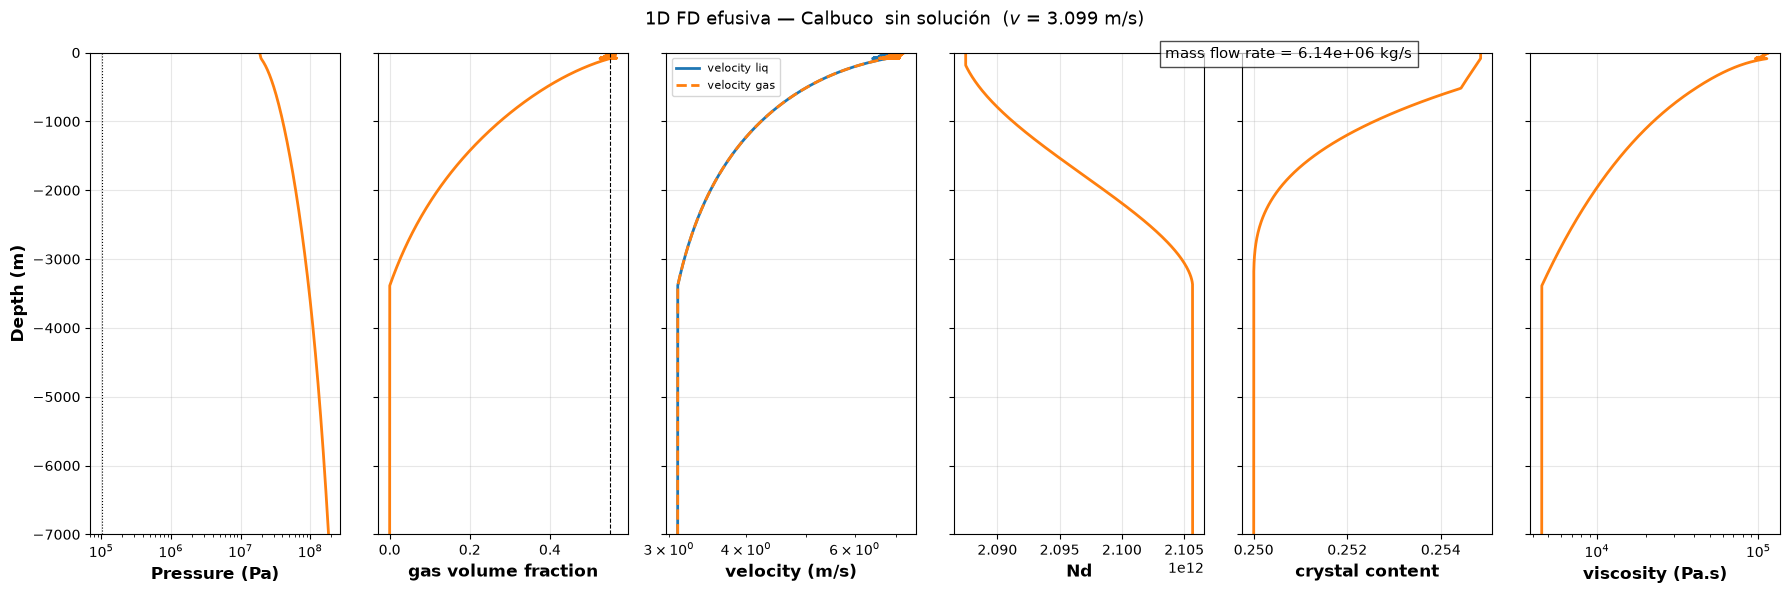

In [8]:
fig, axs = plt.subplots(1, 6, figsize=(18, 6), sharey=True)
titulo = (
    rf"1D FD efusiva — Calbuco  $v_\mathrm{{in}}$ = {vef:.3f} m/s"
    if solef else
    rf"1D FD efusiva — Calbuco  sin solución  ($v$ = {vef:.3f} m/s)"
)
fig.suptitle(titulo, fontsize=13)

axs[0].semilogx(P_ef, zsol_ef, linewidth=2, color="C1")
axs[0].axvline(Patm, color="k", ls=":", lw=0.8)
axs[0].set_xlabel("Pressure (Pa)", fontweight="bold", fontsize=12)
axs[0].set_ylabel("Depth (m)", fontweight="bold", fontsize=12)

axs[1].plot(phi_ef, zsol_ef, linewidth=2, color="C1")
axs[1].axvline(phicrit_ef, color="k", ls="--", lw=0.8)
axs[1].set_xlabel("gas volume fraction", fontweight="bold", fontsize=12)

axs[2].semilogx(um_ef, zsol_ef, label="velocity liq", linewidth=2, color="C0")
axs[2].semilogx(ug_ef, zsol_ef, "--", label="velocity gas", linewidth=2, color="C1")
axs[2].set_xlabel("velocity (m/s)", fontweight="bold", fontsize=12)
axs[2].legend(fontsize=8)

str2 = f"mass flow rate = {Q_ef * rho_ti_ef:.3g} kg/s"
fig.text(0.65, 0.90, str2, fontsize=11, bbox=dict(facecolor="white", alpha=0.7))

axs[3].plot(Nd_ef, zsol_ef, linewidth=2, color="C1")
axs[3].set_xlabel("Nd", fontweight="bold", fontsize=12)

axs[4].plot(x_cr_ef, zsol_ef, linewidth=2, color="C1")
axs[4].set_xlabel("crystal content", fontweight="bold", fontsize=12)

axs[5].semilogx(visc_ef, zsol_ef, linewidth=2, color="C1")
axs[5].set_xlabel("viscosity (Pa.s)", fontweight="bold", fontsize=12)

for ax in axs:
    ax.set_ylim(zsol_ef.min(), 0)
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

Presión, $\varphi$ y velocidades (profundidad en km). En la efusiva $u_m$ y $u_g$ van juntas: no se fragmenta, el flujo es HEM.

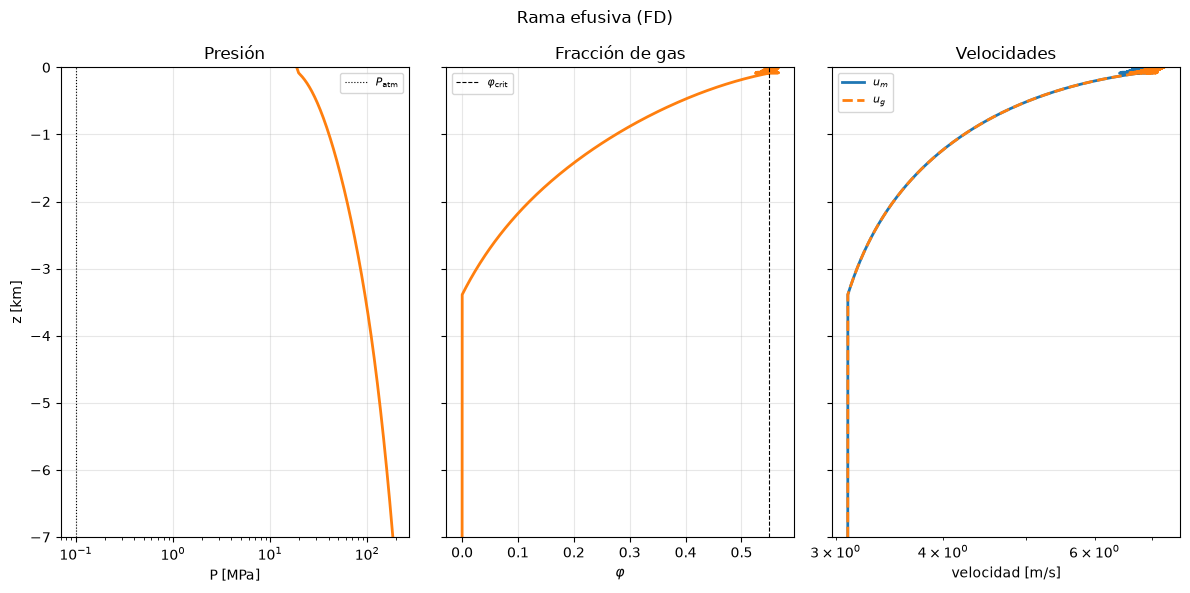

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharey=True)

axes[0].semilogx(P_ef / 1e6, z_km_ef, linewidth=2, color="C1")
axes[0].axvline(Patm / 1e6, color="k", ls=":", lw=0.8, label=r"$P_\mathrm{atm}$")
axes[0].set_xlabel("P [MPa]")
axes[0].set_ylabel("z [km]")
axes[0].set_title("Presión")
axes[0].legend(fontsize=8)

axes[1].plot(phi_ef, z_km_ef, linewidth=2, color="C1")
axes[1].axvline(phicrit_ef, color="k", ls="--", lw=0.8, label=r"$\varphi_\mathrm{crit}$")
axes[1].set_xlabel(r"$\varphi$")
axes[1].set_title("Fracción de gas")
axes[1].legend(fontsize=8)

axes[2].semilogx(um_ef, z_km_ef, linewidth=2, label=r"$u_m$")
axes[2].semilogx(ug_ef, z_km_ef, "--", linewidth=2, label=r"$u_g$")
axes[2].set_xlabel("velocidad [m/s]")
axes[2].set_title("Velocidades")
axes[2].legend(fontsize=8)

for ax in axes:
    ax.set_ylim(z_km_ef.min(), 0)
    ax.grid(True, alpha=0.3)
fig.suptitle("Rama efusiva (FD)")
fig.tight_layout()
plt.show()